# Machine Learning Assisted Compiler for Healthcare Application Code Analysis
**Compiler Design Lab — Jupyter Notebook**

This educational prototype demonstrates lexical analysis, syntax analysis, semantic analysis, healthcare-oriented heuristic checks, and ML-assisted classification.

> Safety note: this is an academic prototype, not a clinical validation tool. Healthcare checks are illustrative; do not use it to assess real clinical software or medication doses.

## 1. Install and import dependencies

In [1]:
import sys, subprocess, importlib.util
if importlib.util.find_spec("sklearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-learn", "pandas", "matplotlib"])
import re, json
from dataclasses import dataclass
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
print("Environment ready")

Environment ready


## 2. Lexical analysis
Converts source code into tokens and reports invalid characters.

In [2]:
KEYWORDS = {"int","float","bool","string","if","else","return","true","false"}
OPS2 = {"==","!=","<=",">=","&&","||"}
PUNCT = set(";(),{}")
OPS1 = set("+-*/%=<>!")
@dataclass
class Token:
    kind: str
    value: str
    line: int
    column: int
class LexError(Exception): pass

def tokenize(src):
    out=[]; i=0; line=1; col=1
    while i<len(src):
        c=src[i]
        if c in " \t\r": i+=1; col+=1; continue
        if c=="\n": i+=1; line+=1; col=1; continue
        if src.startswith("//",i):
            while i<len(src) and src[i]!="\n": i+=1; col+=1
            continue
        if c.isalpha() or c=="_":
            start,sc=i,col
            while i<len(src) and (src[i].isalnum() or src[i]=="_"): i+=1; col+=1
            v=src[start:i]; out.append(Token("KEYWORD" if v in KEYWORDS else "IDENTIFIER",v,line,sc)); continue
        if c.isdigit():
            start,sc=i,col
            while i<len(src) and src[i].isdigit(): i+=1; col+=1
            kind="INTEGER"
            if i<len(src) and src[i]==".":
                i+=1; col+=1
                if i==len(src) or not src[i].isdigit(): raise LexError(f"Malformed number at {line}:{sc}")
                while i<len(src) and src[i].isdigit(): i+=1; col+=1
                kind="FLOAT"
            out.append(Token(kind,src[start:i],line,sc)); continue
        if c=='"':
            sc=col; i+=1; col+=1; val=""
            while i<len(src) and src[i]!='"':
                if src[i]=="\n": raise LexError(f"Unterminated string at {line}:{sc}")
                val+=src[i]; i+=1; col+=1
            if i>=len(src): raise LexError(f"Unterminated string at {line}:{sc}")
            i+=1; col+=1; out.append(Token("STRING",val,line,sc)); continue
        pair=src[i:i+2]
        if pair in OPS2: out.append(Token("OP",pair,line,col)); i+=2; col+=2; continue
        if c in PUNCT or c in OPS1:
            out.append(Token("PUNCT" if c in PUNCT else "OP",c,line,col)); i+=1; col+=1; continue
        raise LexError(f"Invalid character {c!r} at {line}:{col}")
    out.append(Token("EOF","",line,col))
    return out

pd.DataFrame([t.__dict__ for t in tokenize("int patient_age = 42; float weight = 68.5;") if t.kind!="EOF"])

,kind,value,line,column
0,KEYWORD,int,1,1
1,IDENTIFIER,patient_age,1,5
2,OP,=,1,17
3,INTEGER,42,1,19
4,PUNCT,;,1,21
5,KEYWORD,float,1,23
6,IDENTIFIER,weight,1,29
7,OP,=,1,36
8,FLOAT,68.5,1,38
9,PUNCT,;,1,42


## 3. Syntax analysis
Recursive-descent parser for a small C-like language subset.

In [3]:
@dataclass
class Node:
    kind: str
    value: str = ""
    children: list = None
    line: int = 1
    def __post_init__(self):
        if self.children is None: self.children=[]
class ParseError(Exception): pass

class Parser:
    prec={"||":1,"&&":2,"==":3,"!=":3,"<":4,">":4,"<=":4,">=":4,"+":5,"-":5,"*":6,"/":6,"%":6}
    def __init__(self,tokens): self.t=tokens; self.i=0
    def cur(self): return self.t[self.i]
    def eat(self,v=None,k=None):
        t=self.cur()
        if v is not None and t.value!=v: raise ParseError(f"Expected {v!r}, found {t.value!r} at {t.line}:{t.column}")
        if k is not None and t.kind!=k: raise ParseError(f"Expected {k}, found {t.kind} at {t.line}:{t.column}")
        self.i+=1; return t
    def parse(self):
        ss=[]
        while self.cur().kind!="EOF": ss.append(self.stmt())
        return Node("program",children=ss)
    def stmt(self):
        t=self.cur()
        if t.value in {"int","float","bool","string"}:
            typ=self.eat().value; name=self.eat(k="IDENTIFIER"); kids=[Node("type",typ,line=t.line)]
            if self.cur().value=="=": self.eat("="); kids.append(self.expr())
            self.eat(";"); return Node("decl",name.value,kids,t.line)
        if t.value=="return":
            self.eat("return"); e=self.expr(); self.eat(";"); return Node("return",children=[e],line=t.line)
        if t.value=="if":
            self.eat("if"); self.eat("("); cond=self.expr(); self.eat(")")
            then=self.block(); kids=[cond,Node("block",children=then,line=t.line)]
            if self.cur().value=="else": self.eat("else"); kids.append(Node("block",children=self.block(),line=t.line))
            return Node("if",children=kids,line=t.line)
        if t.kind=="IDENTIFIER":
            name=self.eat(k="IDENTIFIER"); self.eat("="); e=self.expr(); self.eat(";")
            return Node("assign",name.value,[e],name.line)
        raise ParseError(f"Unexpected token {t.value!r} at {t.line}:{t.column}")
    def block(self):
        self.eat("{"); ss=[]
        while self.cur().value!="}":
            if self.cur().kind=="EOF": raise ParseError("Unclosed block")
            ss.append(self.stmt())
        self.eat("}"); return ss
    def expr(self,minp=1):
        left=self.prefix()
        while self.cur().value in self.prec and self.prec[self.cur().value]>=minp:
            op=self.eat().value; left=Node("binary",op,[left,self.expr(self.prec[op]+1)],left.line)
        return left
    def prefix(self):
        t=self.cur()
        if t.value in {"!","-"}: op=self.eat().value; return Node("unary",op,[self.expr(7)],t.line)
        if t.value=="(": self.eat("("); e=self.expr(); self.eat(")"); return e
        if t.kind in {"INTEGER","FLOAT","STRING"} or t.value in {"true","false"}:
            self.eat(); return Node("literal",t.value,line=t.line)
        if t.kind=="IDENTIFIER": self.eat(); return Node("identifier",t.value,line=t.line)
        raise ParseError(f"Expected expression, found {t.value!r} at {t.line}:{t.column}")
def parse(tokens): return Parser(tokens).parse()
print("Parser ready.")

Parser ready.


## 4. Semantic analysis
Checks symbol declarations and basic type compatibility.

In [4]:
def semantic_analyze(ast):
    findings=[]; symbols={}; numeric={"int","float"}
    def err(code,msg,line): findings.append({"phase":"semantic","code":code,"message":msg,"line":line})
    def infer(n):
        if n.kind=="literal":
            if n.value in {"true","false"}: return "bool"
            if n.value.replace(".","",1).isdigit(): return "float" if "." in n.value else "int"
            return "string"
        if n.kind=="identifier":
            if n.value not in symbols: err("UNDECLARED_IDENTIFIER",f"'{n.value}' used before declaration.",n.line); return "unknown"
            return symbols[n.value]
        if n.kind=="binary":
            a,b=infer(n.children[0]),infer(n.children[1])
            if "unknown" in {a,b}: return "unknown"
            if n.value in {"+","-","*","/","%"}:
                if a not in numeric or b not in numeric: err("TYPE_MISMATCH",f"Operator {n.value} requires numeric operands.",n.line); return "unknown"
                return "float" if "float" in {a,b} or n.value=="/" else "int"
            if n.value in {"<",">","<=",">=","==","!=","&&","||"}: return "bool"
        if n.kind=="unary": return "bool" if n.value=="!" else infer(n.children[0])
        return "unknown"
    def walk(n):
        if n.kind in {"program","block"}:
            for c in n.children: walk(c)
        elif n.kind=="decl":
            typ=n.children[0].value
            if n.value in symbols: err("DUPLICATE_DECLARATION",f"'{n.value}' already declared.",n.line)
            else: symbols[n.value]=typ
            if len(n.children)>1:
                actual=infer(n.children[1])
                if actual!="unknown" and actual!=typ and not (typ=="float" and actual=="int"):
                    err("TYPE_MISMATCH",f"Cannot initialize {typ} with {actual}.",n.line)
        elif n.kind=="assign":
            actual=infer(n.children[0])
            if n.value not in symbols: err("UNDECLARED_IDENTIFIER",f"Assignment to undeclared '{n.value}'.",n.line)
            elif actual!="unknown" and actual!=symbols[n.value] and not (symbols[n.value]=="float" and actual=="int"):
                err("TYPE_MISMATCH",f"Cannot assign {actual} to {symbols[n.value]}.",n.line)
        elif n.kind=="if":
            if infer(n.children[0]) not in {"bool","unknown"}: err("CONDITION_NOT_BOOLEAN","If condition should be boolean.",n.line)
            walk(n.children[1])
            if len(n.children)>2: walk(n.children[2])
        elif n.kind=="return": infer(n.children[0])
    walk(ast)
    return findings,symbols

## 5. Healthcare-oriented checks
These are illustrative pattern-based warnings, not clinical safety determinations.

In [5]:
def healthcare_checks(source):
    findings=[]
    medical=bool(re.search(r"\b(patient|dose|dosage|medication|drug|weight|glucose|blood_pressure|temperature|lab_result)\b",source,re.I))
    validation=bool(re.search(r"\b(if|assert|validate|check|limit|min|max|range)\b|<=|>=",source,re.I))
    dose_calc=bool(re.search(r"\b(dose|dosage)\s*=\s*[^;]*(?:\*|/|\+|-)",source,re.I))
    if medical and not validation:
        findings.append({"phase":"healthcare_rule","code":"POTENTIAL_MISSING_VALIDATION","message":"Healthcare-related identifiers appear without an obvious validation/check construct.","line":1})
    if dose_calc and not re.search(r"\b(if|assert|validate|check)\b",source,re.I):
        findings.append({"phase":"healthcare_rule","code":"POTENTIAL_DOSE_GUARD_MISSING","message":"Dose/dosage calculation found without an obvious guard.","line":1})
    return findings

## 6. Train the ML classifier
This tiny synthetic dataset demonstrates integration only; it is not suitable for claiming meaningful model accuracy.

In [6]:
training = [
("invalid character lexical token","lexical_error"),("unterminated string invalid token","lexical_error"),
("unexpected token missing semicolon syntax grammar","syntax_error"),("missing brace malformed expression","syntax_error"),
("identifier used before declaration undeclared variable","semantic_error"),("type mismatch incompatible variable","semantic_error"),
("numeric operator requires numeric operands","semantic_error"),
("healthcare patient values without validation range check","potential_safety_risk"),
("dosage calculation without guard boundary validation","potential_safety_risk"),("dose weight calculation missing safety check","potential_safety_risk"),
("program has no findings checks passed","no_issue"),("tokens parsed types consistent","no_issue"),
("source passes lexical syntax semantic analysis","no_issue"),("lab result missing validation","potential_safety_risk")
]
ml_model=Pipeline([("tfidf",TfidfVectorizer(ngram_range=(1,2))),("tree",DecisionTreeClassifier(max_depth=5,random_state=7,class_weight="balanced"))])
ml_model.fit([x for x,y in training],[y for x,y in training])
print("ML classifier trained on",len(training),"synthetic examples.")

ML classifier trained on 14 synthetic examples.


## 7. Complete analysis pipeline

In [7]:
def analyze_source(source):
    findings=[]; tokens=[]; symbols={}
    try: tokens=tokenize(source)
    except LexError as e:
        findings.append({"phase":"lexical","code":"LEXICAL_ERROR","message":str(e),"line":1})
        return make_report(tokens,symbols,findings)
    try: ast=parse(tokens)
    except ParseError as e:
        findings.append({"phase":"syntax","code":"SYNTAX_ERROR","message":str(e),"line":1})
        findings.extend(healthcare_checks(source))
        return make_report(tokens,symbols,findings)
    sf,symbols=semantic_analyze(ast)
    findings.extend(sf); findings.extend(healthcare_checks(source))
    return make_report(tokens,symbols,findings)

def make_report(tokens,symbols,findings):
    fixed={"lexical":"lexical_error","syntax":"syntax_error","semantic":"semantic_error"}
    classified=[]
    for f in findings:
        cat=fixed.get(f["phase"])
        if cat is None: cat=ml_model.predict([f"{f['phase']} {f['code']} {f['message']}"])[0]
        classified.append({"code":f["code"],"phase":f["phase"],"predicted_category":cat,"message":f["message"]})
    return {"status":"PASSED" if not findings else "REVIEW_REQUIRED",
            "tokens":[t.__dict__ for t in tokens if t.kind!="EOF"],
            "symbols":symbols,"findings":findings,"ml_classifications":classified}

## 8. Run example programs

In [8]:
samples={
"valid_patient.c": """int patient_age = 42;
float body_weight = 68.5;
bool input_valid = true;
if (input_valid == true) { float measured_value = body_weight + 1.0; return patient_age; }
""",
"potential_risk.c": """float weight = 68.5;
float dose = weight * 10.0;
return dose;
""",
"syntax_error.c": """int patient_age = 42
float dose = patient_age * 10.0;
return dose;
""",
"semantic_error.c": """int patient_age = "forty";
dose = patient_age * 2;
"""
}
results={}
for name,src in samples.items():
    r=analyze_source(src); results[name]=r
    print("\\n",name,"=>",r["status"])
    print("Symbol table:",r["symbols"])
    for f in r["findings"]: print("-",f["phase"],f["code"],":",f["message"])
    print("ML categories:",[x["predicted_category"] for x in r["ml_classifications"]])

\n valid_patient.c => PASSED
Symbol table: {'patient_age': 'int', 'body_weight': 'float', 'input_valid': 'bool', 'measured_value': 'float'}
ML categories: []
\n potential_risk.c => REVIEW_REQUIRED
Symbol table: {'weight': 'float', 'dose': 'float'}
- healthcare_rule POTENTIAL_MISSING_VALIDATION : Healthcare-related identifiers appear without an obvious validation/check construct.
- healthcare_rule POTENTIAL_DOSE_GUARD_MISSING : Dose/dosage calculation found without an obvious guard.
ML categories: [np.str_('no_issue'), np.str_('potential_safety_risk')]
\n syntax_error.c => REVIEW_REQUIRED
Symbol table: {}
- syntax SYNTAX_ERROR : Expected ';', found 'float' at 2:1
- healthcare_rule POTENTIAL_MISSING_VALIDATION : Healthcare-related identifiers appear without an obvious validation/check construct.
- healthcare_rule POTENTIAL_DOSE_GUARD_MISSING : Dose/dosage calculation found without an obvious guard.
ML categories: ['syntax_error', np.str_('no_issue'), np.str_('potential_safety_risk')]
\n 

## 9. View detailed JSON output

In [9]:
selected_sample = "potential_risk.c"  # Change this value to inspect another sample
print(json.dumps(results[selected_sample], indent=2))

{
  "status": "REVIEW_REQUIRED",
  "tokens": [
    {
      "kind": "KEYWORD",
      "value": "float",
      "line": 1,
      "column": 1
    },
    {
      "kind": "IDENTIFIER",
      "value": "weight",
      "line": 1,
      "column": 7
    },
    {
      "kind": "OP",
      "value": "=",
      "line": 1,
      "column": 14
    },
    {
      "kind": "FLOAT",
      "value": "68.5",
      "line": 1,
      "column": 16
    },
    {
      "kind": "PUNCT",
      "value": ";",
      "line": 1,
      "column": 20
    },
    {
      "kind": "KEYWORD",
      "value": "float",
      "line": 2,
      "column": 1
    },
    {
      "kind": "IDENTIFIER",
      "value": "dose",
      "line": 2,
      "column": 7
    },
    {
      "kind": "OP",
      "value": "=",
      "line": 2,
      "column": 12
    },
    {
      "kind": "IDENTIFIER",
      "value": "weight",
      "line": 2,
      "column": 14
    },
    {
      "kind": "OP",
      "value": "*",
      "line": 2,
      "column": 21
    },
   

## 10. Automated functional tests

In [10]:
test_cases=[
("lexical error","int age = 3; @",lambda r:any(f["phase"]=="lexical" for f in r["findings"])),
("syntax error","int age = 3",lambda r:any(f["phase"]=="syntax" for f in r["findings"])),
("undeclared variable","int age = 3; dose = age * 2;",lambda r:any(f["code"]=="UNDECLARED_IDENTIFIER" for f in r["findings"])),
("healthcare rule","float dose = weight * 10.0;",lambda r:any(f["code"]=="POTENTIAL_DOSE_GUARD_MISSING" for f in r["findings"]))
]
test_results=pd.DataFrame([{"test":n,"result":"PASS" if check(analyze_source(src)) else "FAIL"} for n,src,check in test_cases])
display(test_results)
print("Passed:",(test_results.result=="PASS").sum(),"/",len(test_results))

,test,result
0,lexical error,PASS
1,syntax error,PASS
2,undeclared variable,PASS
3,healthcare rule,PASS


Passed: 4 / 4


## 11. Results summary and charts

,sample,phase,code
0,potential_risk.c,healthcare_rule,POTENTIAL_MISSING_VALIDATION
1,potential_risk.c,healthcare_rule,POTENTIAL_DOSE_GUARD_MISSING
2,syntax_error.c,syntax,SYNTAX_ERROR
3,syntax_error.c,healthcare_rule,POTENTIAL_MISSING_VALIDATION
4,syntax_error.c,healthcare_rule,POTENTIAL_DOSE_GUARD_MISSING
5,semantic_error.c,semantic,TYPE_MISMATCH
6,semantic_error.c,semantic,UNDECLARED_IDENTIFIER
7,semantic_error.c,healthcare_rule,POTENTIAL_MISSING_VALIDATION
8,semantic_error.c,healthcare_rule,POTENTIAL_DOSE_GUARD_MISSING


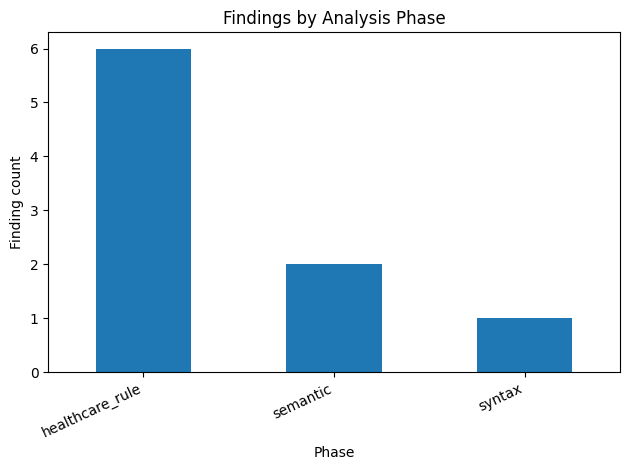

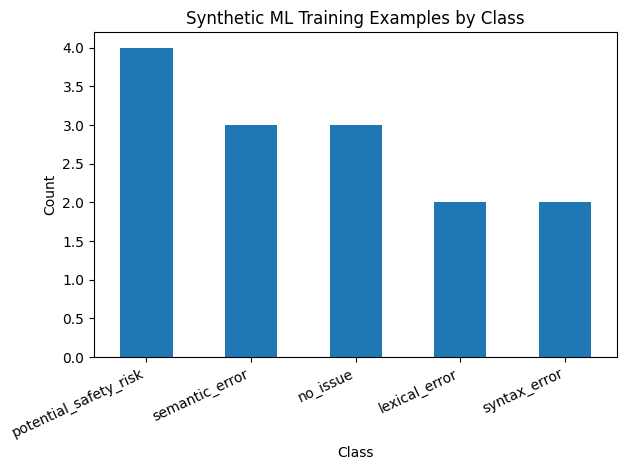

In [11]:
rows=[{"sample":name,"phase":f["phase"],"code":f["code"]} for name,r in results.items() for f in r["findings"]]
findings_df=pd.DataFrame(rows)
display(findings_df)
if not findings_df.empty:
    findings_df.groupby("phase").size().plot(kind="bar")
    plt.title("Findings by Analysis Phase"); plt.xlabel("Phase"); plt.ylabel("Finding count")
    plt.xticks(rotation=25,ha="right"); plt.tight_layout(); plt.show()
pd.Series([y for x,y in training]).value_counts().plot(kind="bar")
plt.title("Synthetic ML Training Examples by Class"); plt.xlabel("Class"); plt.ylabel("Count")
plt.xticks(rotation=25,ha="right"); plt.tight_layout(); plt.show()

## 12. Export outputs for your lab report

In [12]:
with open("healthcare_compiler_results.json","w",encoding="utf-8") as f: json.dump(results,f,indent=2)
test_results.to_csv("compiler_test_results.csv",index=False)
findings_df.to_csv("compiler_findings_summary.csv",index=False)
print("Saved JSON report, test results CSV, and findings CSV in the notebook working directory.")

Saved JSON report, test results CSV, and findings CSV in the notebook working directory.


## 13. Conclusion and limitations
This notebook combines a lexer, recursive-descent parser, symbol-table semantic checks, healthcare-oriented heuristics and a Decision Tree classifier.

Limitations to state in the report:
- Only a small C-like language subset is supported.
- Healthcare checks may produce false positives or false negatives.
- The ML dataset is small and synthetic; do not claim validated accuracy.
- The prototype is not for clinical deployment and must not be used with real patient data.